# Single-neuron Euclidean distance across conditions

Network version of the A1 single-neuron analysis (raincloud plots): for every neuron the Euclidean distance between its trial-averaged Go and No-Go responses, its trial-to-trial noise (SD), and the distance normalised by that noise.

**Per neuron** (responsive units, Z-scored, response averaged over the window 0–300 ms):

* `dist` = |mean Go − mean No-Go|  (single-neuron Euclidean distance)
* `sd` = pooled within-class SD across trials (noise of that neuron)
* `dist_norm` = `dist` / `sd`  (distance in units of the neuron's own noise)

**Conditions** are set in `CONDITIONS` (model, checkpoint step, stimulus set); **comparisons** in `COMPARISONS`. Models come from the same `MODEL_DIRs` as in `neuron_discrimination.ipynb`.

**Plot**: small dots = individual neurons, large circles = per-"animal" means, horizontal bar = group median, half-violin = distribution. p-values: hierarchical bootstrap (animals resampled, then neurons within each animal).

*Caveat*: an "animal" here is one **session** (an independent simulation with its own trials and noise) of a trained network, not an independent trained network. With one network per group the bootstrap captures session-to-session and neuron sampling variability, not variability between training runs.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

sys.path.insert(0, os.getcwd())
import population_geometry as pg
%matplotlib inline

In [2]:
# ── set up ────────────────────────────────────────────────────────────────
env_file = Path.cwd().parent / '.env'
if env_file.exists():
    for line in env_file.read_text().splitlines():
        line = line.strip()
        if '=' in line and not line.startswith('#'):
            key, _, val = line.partition('=')
            os.environ.setdefault(key.strip(), val.strip())

results_dir = Path(os.environ.get('TONE_RESULTS_DIR', ''))
if not results_dir:
    sys.exit('TONE_RESULTS_DIR is not set. Add it to .env or export it.')

# models: same as MODEL_DIRs in neuron_discrimination.ipynb (all dirs of a label are used)
MODEL_DIRs = {
    'PT': [results_dir / 'pure/pure_0_lr0.0001_bs64_noise0.1_nrnn128'],
    'HCT': [results_dir / 'harmonic/harmonic_0_lr0.0001_bs64_noise0.1_nrnn128'],
    'PT-HCT': [results_dir / 'transfer_pure_to_harmonic/all/harmonic/harmonic_0_lr0.0001_bs64_noise0.1_nrnn128_src4000'],
}

# conditions: name -> model (key of MODEL_DIRs), checkpoint step, stimulus set, colour
#   day 3                          = step 4000 of the model trained from scratch
#   switch day                     = step 200 of the transferred model
#   switch day, first 100 trials   = step 0 of the transferred model = checkpoint_init
#                                    (the source network before any training on the new task)
CONDITIONS = {
    'PT (day 3)':                  dict(model='PT',     step=4000, task='pure',     color='#E4572E'),
    'HCT (day 3)':                 dict(model='HCT',    step=4000, task='harmonic', color='#2E86C1'),
    'PT-HCT (switch day)':         dict(model='PT-HCT', step=200,  task='harmonic', color='#6AAB3B'),
    'PT-HCT (switch day, first 100 trials)': dict(model='PT-HCT', step=0, task='harmonic', color='#6AAB3B'),
}

# comparisons shown as columns: (condition A, condition B); the test is B - A
COMPARISONS = [
    ('PT (day 3)',  'HCT (day 3)'),
    ('HCT (day 3)', 'PT-HCT (switch day)'),
    ('HCT (day 3)', 'PT-HCT (switch day, first 100 trials)'),
]

N_SESSIONS = 10              # simulated sessions per model and condition (= "animals")
N_TRIALS   = 200             # trials per session
WINDOW_MS  = (0, 300)        # response window (ms from stimulus onset)
ZSCORE     = 'all'           # 'all' | 'baseline' | None  (see neuron_discrimination.select_units)
RESPONSIVE_ONLY = True       # True: responsive units only; False: all units
N_BOOT     = 10000           # hierarchical bootstrap iterations
STAT       = 'median'        # statistic compared by the bootstrap: 'median' | 'mean'
YCLIP_PCT  = 99.5            # y-axis upper limit = this percentile of the plotted values (display only)

MEASURES = [('dist',      'single-neuron Euclidean distance'),
            ('sd',        'single-neuron SD (trial-to-trial)'),
            ('dist_norm', 'distance / SD')]

In [3]:
# per-neuron statistics of every condition
cond_data = {}
for name, c in CONDITIONS.items():
    cond_data[name] = pg.run_neuron_condition(
        MODEL_DIRs[c['model']], c['task'], c['step'], n_sessions=N_SESSIONS, n_trials=N_TRIALS,
        window_ms=WINDOW_MS, zscore=ZSCORE, responsive_only=RESPONSIVE_ONLY)
    a = cond_data[name]
    print(f'{name:40s} {c["model"]:7s} step {c["step"]:5d} {c["task"]:9s} '
          f'animals = {len(a)}, neurons per animal = {np.mean([len(x["units"]) for x in a]):.0f}')

PT (day 3)                               PT      step  4000 pure      animals = 10, neurons per animal = 58
HCT (day 3)                              HCT     step  4000 harmonic  animals = 10, neurons per animal = 61
PT-HCT (switch day)                      PT-HCT  step   200 harmonic  animals = 10, neurons per animal = 57
  step 0: using checkpoint_init.pkl  [C:\Users\zhixi\Documents\data\results\tone_generalize\transfer_pure_to_harmonic\all\harmonic\harmonic_0_lr0.0001_bs64_noise0.1_nrnn128_src4000]
PT-HCT (switch day, first 100 trials)    PT-HCT  step     0 harmonic  animals = 10, neurons per animal = 54


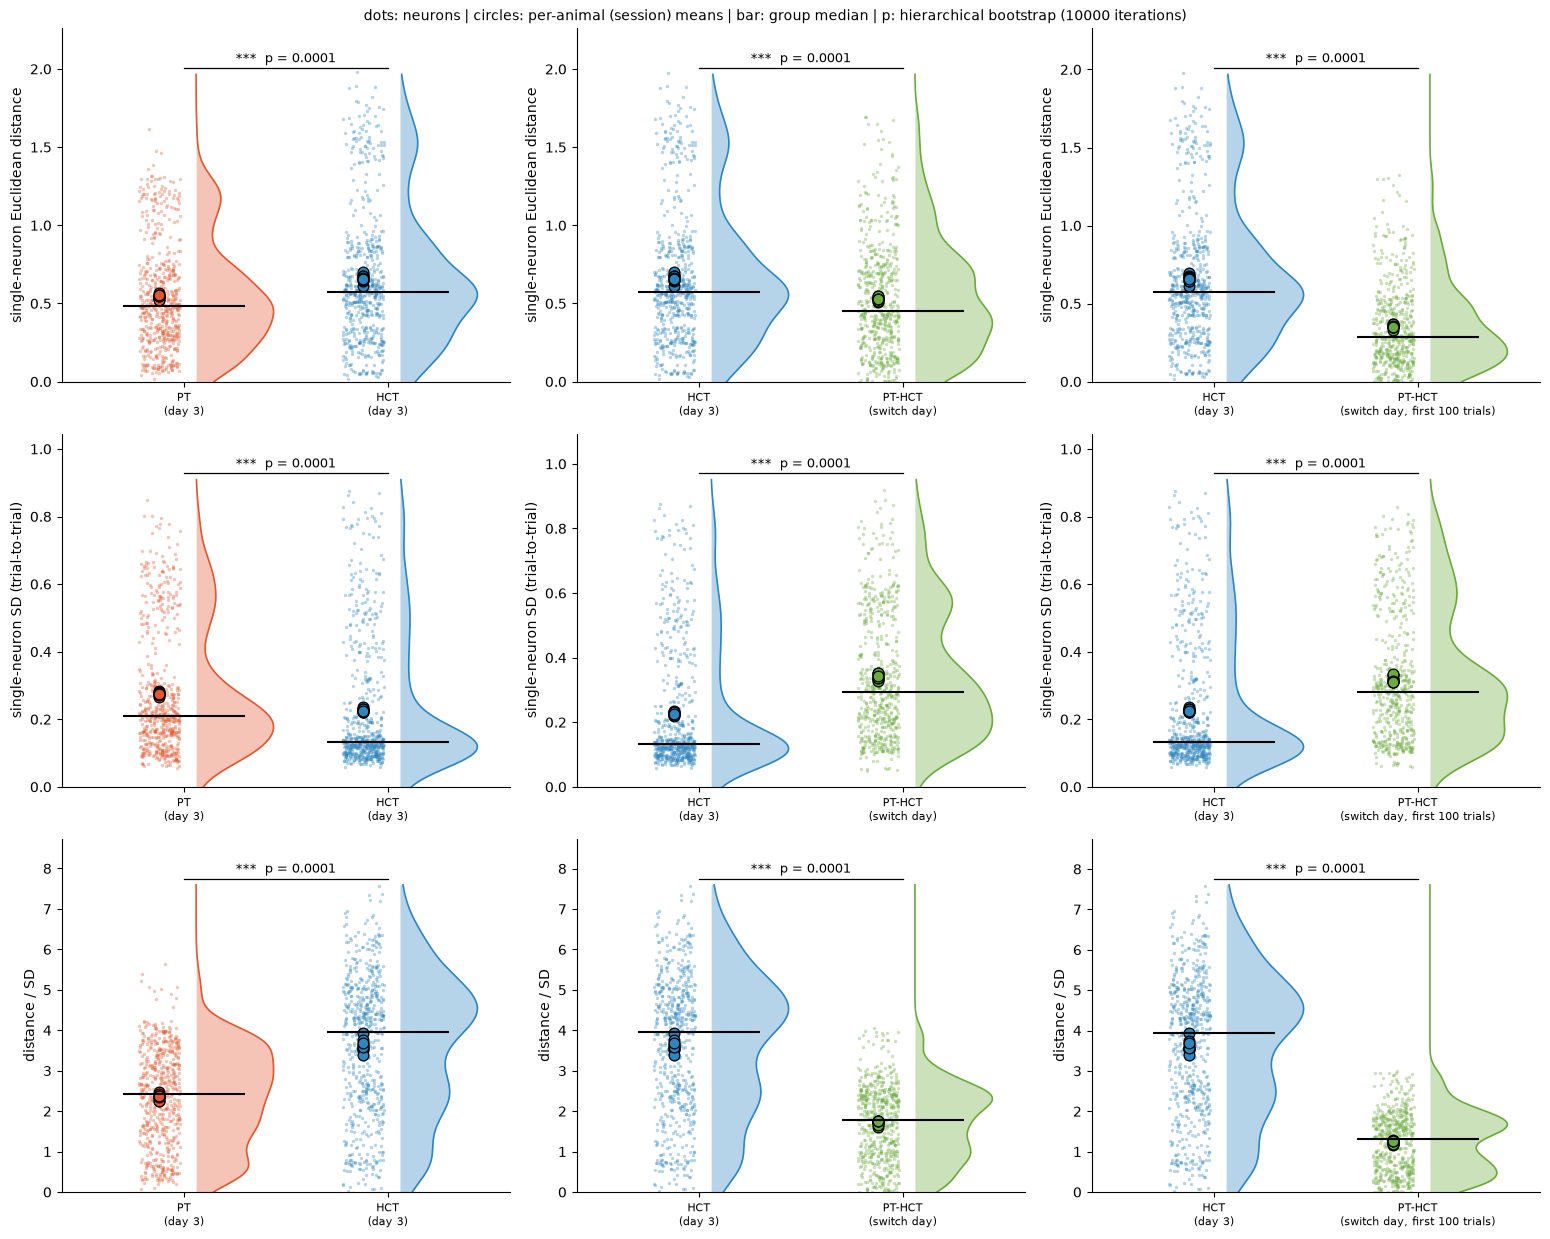

In [4]:
# ── raincloud plots: rows = measure, columns = comparison ───────────────────────────
def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'


def raincloud(ax, animals, x, color, ytop):
    """dots = neurons, large circles = animal means, bar = median, half-violin = density."""
    vals_per_animal = [np.asarray(a[KEY], float)[np.isfinite(a[KEY])] for a in animals]
    vals = np.concatenate(vals_per_animal)
    rng = np.random.default_rng(0)
    ax.scatter(x - 0.12 + rng.uniform(-0.1, 0.1, len(vals)), vals, s=6, color=color, alpha=0.35,
               linewidths=0, zorder=2)
    v = vals[vals <= ytop]
    if len(v) > 5 and v.std() > 0:
        grid = np.linspace(0, ytop, 200)
        dens = gaussian_kde(v)(grid)
        ax.fill_betweenx(grid, x + 0.06, x + 0.06 + 0.38 * dens / dens.max(), color=color, alpha=0.35, lw=0)
        ax.plot(x + 0.06 + 0.38 * dens / dens.max(), grid, color=color, lw=1.2)
    ax.scatter(np.full(len(vals_per_animal), x - 0.12), [np.mean(a) for a in vals_per_animal], s=60,
               color=color, edgecolor='k', linewidths=0.9, zorder=4)           # per-animal means
    ax.hlines(np.median(vals), x - 0.3, x + 0.3, color='k', lw=1.5, zorder=5)  # group median


def short(name):
    return name.replace(' (', '\n(')


fig, axes = plt.subplots(len(MEASURES), len(COMPARISONS), figsize=(5.2 * len(COMPARISONS), 4.2 * len(MEASURES)),
                         squeeze=False)
stat_rows = []
for i, (KEY, mname) in enumerate(MEASURES):
    for j, (A, B) in enumerate(COMPARISONS):
        ax = axes[i, j]
        allv = np.concatenate([np.asarray(a[KEY], float) for n in (A, B) for a in cond_data[n]])
        ytop = np.nanpercentile(allv[np.isfinite(allv)], YCLIP_PCT) * 1.1
        for k, n in enumerate((A, B)):
            raincloud(ax, cond_data[n], k, CONDITIONS[n]['color'], ytop)
        r = pg.hierarchical_bootstrap(cond_data[A], cond_data[B], KEY, n_boot=N_BOOT, stat=STAT)
        ax.plot([0, 1], [ytop * 1.02] * 2, color='k', lw=0.9)
        ax.text(0.5, ytop * 1.03, f'{stars(r["p"])}  p = {r["p"]:.2g}', ha='center', va='bottom', fontsize=9)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([short(A), short(B)], fontsize=8)
        ax.set_xlim(-0.6, 1.6)
        ax.set_ylim(0, ytop * 1.15)
        ax.set_ylabel(mname)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
        med = lambda n: np.median(np.concatenate([np.asarray(a[KEY], float)[np.isfinite(a[KEY])] for a in cond_data[n]]))
        stat_rows.append({'measure': mname, 'A': A, 'B': B, f'{STAT} A': med(A), f'{STAT} B': med(B),
                          'B - A': r['diff'], 'CI low': r['ci'][0], 'CI high': r['ci'][1], 'p': r['p'],
                          'animals A/B': f'{len(cond_data[A])}/{len(cond_data[B])}'})
fig.suptitle(f'dots: neurons | circles: per-animal (session) means | bar: group {STAT} | '
             f'p: hierarchical bootstrap ({N_BOOT} iterations)', fontsize=10)
fig.tight_layout()
plt.show()

In [5]:
# statistics behind the plots (B - A, 95% bootstrap interval, hierarchical-bootstrap p)
pd.DataFrame(stat_rows).set_index(['measure', 'A', 'B'])

median A  \
measure                           A           B                                                 
single-neuron Euclidean distance  PT (day 3)  HCT (day 3)                            0.481191   
                                  HCT (day 3) PT-HCT (switch day)                    0.573952   
                                              PT-HCT (switch day, first 100 trials)  0.573952   
single-neuron SD (trial-to-trial) PT (day 3)  HCT (day 3)                            0.210677   
                                  HCT (day 3) PT-HCT (switch day)                    0.133932   
                                              PT-HCT (switch day, first 100 trials)  0.133932   
distance / SD                     PT (day 3)  HCT (day 3)                            2.434702   
                                  HCT (day 3) PT-HCT (switch day)                    3.946328   
                                              PT-HCT (switch day, first 100 trials)  3.946328   

                                                                                     median B  \
measure                           A           B                                                 
single-neuron Euclidean distance  PT (day 3)  HCT (day 3)                            0.573952   
                                  HCT (day 3) PT-HCT (switch day)                    0.451316   
                                              PT-HCT (switch day, first 100 trials)  0.284983   
single-neuron SD (trial-to-trial) PT (day 3)  HCT (day 3)                            0.133932   
                                  HCT (day 3) PT-HCT (switch day)                    0.294226   
                                              PT-HCT (switch day, first 100 trials)  0.280760   
distance / SD                     PT (day 3)  HCT (day 3)                            3.946328   
                                  HCT (day 3) PT-HCT (switch day)                    1.784745   
                                              PT-HCT (switch day, first 100 trials)  1.319421   

                                                                                        B - A  \
measure                           A           B                                                 
single-neuron Euclidean distance  PT (day 3)  HCT (day 3)                            0.092762   
                                  HCT (day 3) PT-HCT (switch day)                   -0.122636   
                                              PT-HCT (switch day, first 100 trials) -0.288969   
single-neuron SD (trial-to-trial) PT (day 3)  HCT (day 3)                           -0.076744   
                                  HCT (day 3) PT-HCT (switch day)                    0.160294   
                                              PT-HCT (switch day, first 100 trials)  0.146828   
distance / SD                     PT (day 3)  HCT (day 3)                            1.511625   
                                  HCT (day 3) PT-HCT (switch day)                   -2.161583   
                                              PT-HCT (switch day, first 100 trials) -2.626907   

                                                                                       CI low  \
measure                           A           B                                                 
single-neuron Euclidean distance  PT (day 3)  HCT (day 3)                            0.059750   
                                  HCT (day 3) PT-HCT (switch day)                   -0.159368   
                                              PT-HCT (switch day, first 100 trials) -0.319026   
single-neuron SD (trial-to-trial) PT (day 3)  HCT (day 3)                           -0.084457   
                                  HCT (day 3) PT-HCT (switch day)                    0.139307   
                                              PT-HCT (switch day, first 100 trials)  0.127076   
distance / SD                     PT (day 3)  HCT (day 3)                            1.195511   
        